In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
data_dir = Path("../data/raw")

with open(data_dir / "MD-Agreement_train.json", "r", encoding="utf-8") as f:
    train_data = json.load(f)

print(type(train_data))
print(len(train_data))

<class 'dict'>
6592


In [3]:
# Inspect the first record
first_key = next(iter(train_data))

print("Record ID:", first_key)
print("Record contents:")
print(json.dumps(train_data[first_key], indent=4, ensure_ascii=False))

Record ID: 1
Record contents:
{
    "text": "<user> <user> No way Jose!!",
    "annotation task": "offensiveness detection",
    "number of annotations": 5,
    "annotations": "0,0,0,0,0",
    "annotators": "Ann418,Ann266,Ann149,Ann730,Ann345",
    "lang": "en",
    "hard_label": "0",
    "soft_label": {
        "0": 1.0,
        "1": 0.0
    },
    "split": "train",
    "other_info": {
        "domain": "Elections2020"
    }
}


In [5]:
# Convert JSON dictionary to DataFrame
train_df = pd.DataFrame.from_dict(train_data, orient="index")
train_df.index.name = "record_id"
train_df.head()

,text,annotation task,number of annotations,annotations,annotators,lang,hard_label,soft_label,split,other_info
record_id,,,,,,,,,,
1,<user> <user> No way Jose!!,offensiveness detection,5,"0,0,0,0,0","Ann418,Ann266,Ann149,Ann730,Ann345",en,0,"{'0': 1.0, '1': 0.0}",train,{'domain': 'Elections2020'}
2,"Good god, what is the matter with people ?",offensiveness detection,5,"0,0,0,0,0","Ann733,Ann422,Ann779,Ann514,Ann777",en,0,"{'0': 1.0, '1': 0.0}",train,{'domain': 'Covid-19'}
3,<user> <user> <user> <user> Um the Kurds are h...,offensiveness detection,5,"0,0,0,0,1","Ann425,Ann511,Ann779,Ann420,Ann721",en,0,"{'0': 0.8, '1': 0.2}",train,{'domain': 'Elections2020'}
4,What is WRONG with these people?,offensiveness detection,5,"0,0,0,0,0","Ann632,Ann179,Ann701,Ann201,Ann661",en,0,"{'0': 1.0, '1': 0.0}",train,{'domain': 'BLM'}
5,<user> This earpiece too plus a wire on his sl...,offensiveness detection,5,"1,0,0,0,0","Ann266,Ann168,Ann149,Ann381,Ann774",en,0,"{'0': 0.8, '1': 0.2}",train,{'domain': 'Elections2020'}


In [6]:
print("Dataset shape:", train_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nDataset info:")
train_df.info()

Dataset shape: (6592, 10)

Columns:
['text', 'annotation task', 'number of annotations', 'annotations', 'annotators', 'lang', 'hard_label', 'soft_label', 'split', 'other_info']

Dataset info:
<class 'pandas.DataFrame'>
Index: 6592 entries, 1 to 6592
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   text                   6592 non-null   str   
 1   annotation task        6592 non-null   str   
 2   number of annotations  6592 non-null   int64 
 3   annotations            6592 non-null   str   
 4   annotators             6592 non-null   str   
 5   lang                   6592 non-null   str   
 6   hard_label             6592 non-null   str   
 7   soft_label             6592 non-null   object
 8   split                  6592 non-null   str   
 9   other_info             6592 non-null   object
dtypes: int64(1), object(2), str(7)
memory usage: 566.5+ KB


In [7]:
# Check missing values
print("Missing values:")
print(train_df.isnull().sum())

# Check duplicated texts
print("\nDuplicated texts:", train_df["text"].duplicated().sum())

# Check empty texts
print("Empty texts:", train_df["text"].str.strip().eq("").sum())

# Check number of annotations
print("\nNumber of annotations:")
print(train_df["number of annotations"].value_counts())

# Check unique labels
print("\nHard labels:")
print(train_df["hard_label"].value_counts())

Missing values:
text                     0
annotation task          0
number of annotations    0
annotations              0
annotators               0
lang                     0
hard_label               0
soft_label               0
split                    0
other_info               0
dtype: int64

Duplicated texts: 0
Empty texts: 0

Number of annotations:
number of annotations
5    6592
Name: count, dtype: int64

Hard labels:
hard_label
0    4630
1    1962
Name: count, dtype: int64


## 2. Exploratory Data Analysis (EDA)

### 2.1 Hard Label Distribution

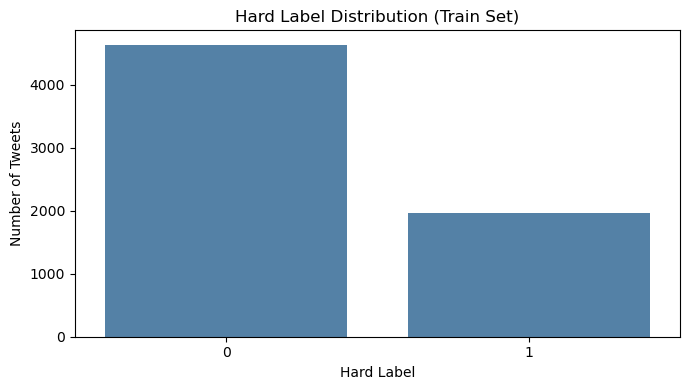

In [8]:
label_counts = train_df["hard_label"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    color="steelblue"
)

plt.title("Hard Label Distribution (Train Set)")
plt.xlabel("Hard Label")
plt.ylabel("Number of Tweets")

plt.tight_layout()
plt.show()

### 2.2 Soft Label Distribution and Annotator Disagreement

In [9]:
# Extract the probability of class 1 (offensive)
train_df["soft_label_1"] = train_df["soft_label"].apply(
    lambda x: float(x["1"])
)

# Extract the probability of class 0 (non-offensive)
train_df["soft_label_0"] = train_df["soft_label"].apply(
    lambda x: float(x["0"])
)

# Examine the distribution
print(train_df["soft_label_1"].value_counts().sort_index())

soft_label_1
0.0    2303
0.2    1295
0.4    1032
0.6     852
0.8     635
1.0     475
Name: count, dtype: int64


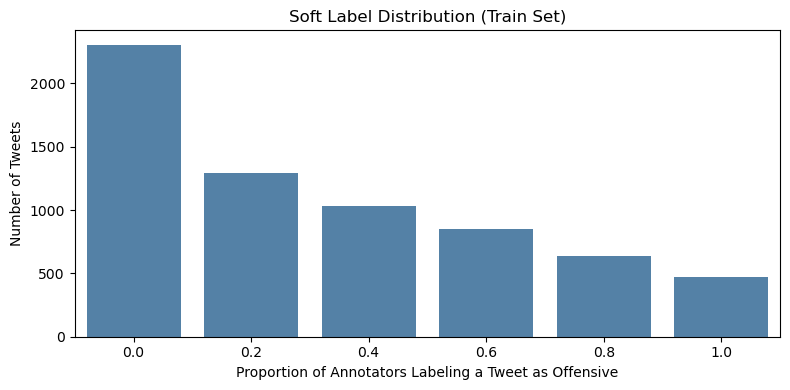

In [10]:
soft_counts = train_df["soft_label_1"].value_counts().sort_index()

plt.figure(figsize=(8, 4))

sns.barplot(
    x=soft_counts.index.astype(str),
    y=soft_counts.values,
    color="steelblue"
)

plt.title("Soft Label Distribution (Train Set)")
plt.xlabel("Proportion of Annotators Labeling a Tweet as Offensive")
plt.ylabel("Number of Tweets")

plt.tight_layout()
plt.show()

### 2.3 Annotation Entropy

In [11]:
def calculate_entropy(row):
    probabilities = [row["soft_label_0"], row["soft_label_1"]]
    
    entropy = 0
    for p in probabilities:
        if p > 0:
            entropy -= p * np.log2(p)
            
    return entropy


train_df["annotation_entropy"] = train_df.apply(
    calculate_entropy, axis=1
)

print(train_df["annotation_entropy"].round(3).value_counts().sort_index())


annotation_entropy
0.000    2778
0.722    1930
0.971    1884
Name: count, dtype: int64


### 2.4 Annotation Entropy Distribution

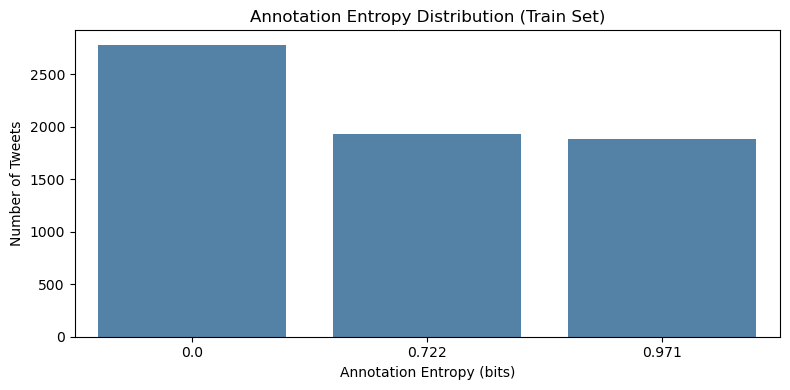

In [12]:
entropy_counts = (
    train_df["annotation_entropy"]
    .round(3)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))

sns.barplot(
    x=entropy_counts.index.astype(str),
    y=entropy_counts.values,
    color="steelblue"
)

plt.title("Annotation Entropy Distribution (Train Set)")
plt.xlabel("Annotation Entropy (bits)")
plt.ylabel("Number of Tweets")

plt.tight_layout()
plt.show()

### 2.5 Annotation Entropy vs. Hard Labels

In [13]:
# Round entropy values for easier grouping
train_df["entropy_level"] = train_df["annotation_entropy"].round(3)

# Count examples by entropy level and hard label
entropy_label_counts = pd.crosstab(
    train_df["entropy_level"],
    train_df["hard_label"]
)

entropy_label_counts


hard_label,0,1
entropy_level,,
0.000,2303,475
0.722,1295,635
0.971,1032,852


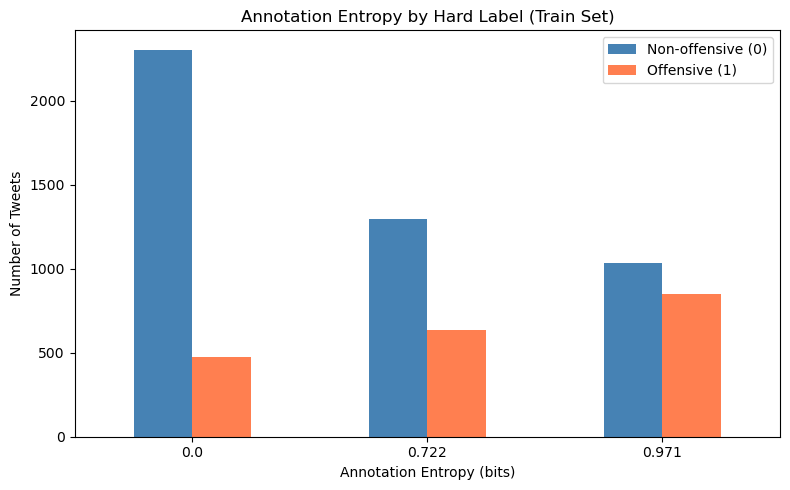

In [14]:

entropy_label_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "coral"]
)

plt.title("Annotation Entropy by Hard Label (Train Set)")
plt.xlabel("Annotation Entropy (bits)")
plt.ylabel("Number of Tweets")
plt.legend(["Non-offensive (0)", "Offensive (1)"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [15]:
# Percentage of each entropy level within each hard-label class
entropy_label_pct = pd.crosstab(
    train_df["entropy_level"],
    train_df["hard_label"],
    normalize="columns"
) * 100

print(entropy_label_pct.round(2))


hard_label         0      1
entropy_level              
0.000          49.74  24.21
0.722          27.97  32.36
0.971          22.29  43.43


### 2.6 Annotation Disagreement by Domain

In [16]:
# Extract domain from the nested dictionary
train_df["domain"] = train_df["other_info"].apply(
    lambda x: x["domain"]
)

# Check domain distribution
print(train_df["domain"].value_counts())


domain
BLM              2351
Covid-19         2206
Elections2020    2035
Name: count, dtype: int64


In [17]:
domain_entropy = (
    train_df.groupby("domain")["annotation_entropy"]
    .agg(["count", "mean", "median"])
    .round(3)
)

print(domain_entropy)


               count   mean  median
domain                             
BLM             2351  0.386   0.000
Covid-19        2206  0.558   0.722
Elections2020   2035  0.533   0.722


entropy_level  0.000  0.722  0.971
domain                            
BLM            53.59  25.90  20.50
Covid-19       34.36  31.82  33.82
Elections2020  37.35  30.42  32.24


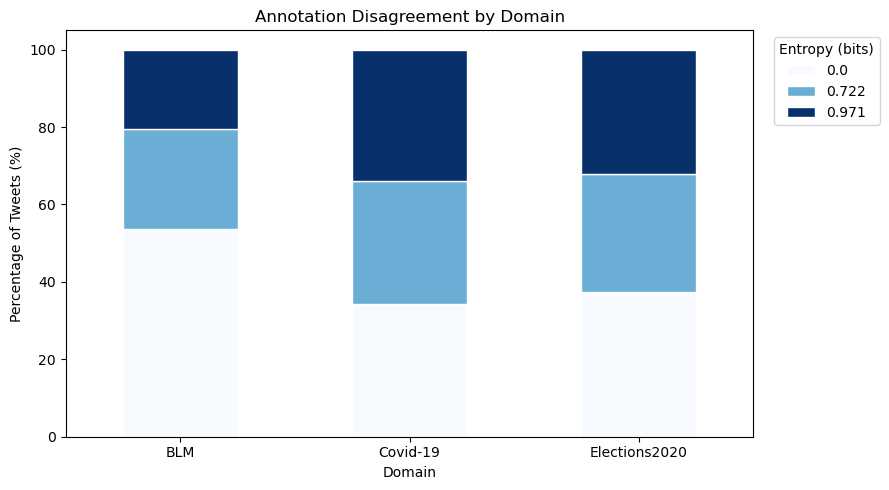

In [18]:
# Calculate percentage distribution of entropy levels by domain
domain_entropy_pct = pd.crosstab(
    train_df["domain"],
    train_df["entropy_level"],
    normalize="index"
) * 100

print(domain_entropy_pct.round(2))

# Plot stacked bar chart
ax = domain_entropy_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Blues",
    edgecolor="white"
)

plt.title("Annotation Disagreement by Domain")
plt.xlabel("Domain")
plt.ylabel("Percentage of Tweets (%)")
plt.legend(
    title="Entropy (bits)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Preparing Data for Model Training

In [19]:
# Load validation and test datasets
with open(data_dir / "MD-Agreement_dev.json", encoding="utf-8") as f:
    dev_data = json.load(f)

with open(data_dir / "MD-Agreement_test.json", encoding="utf-8") as f:
    test_data = json.load(f)

# Convert to DataFrames
dev_df = pd.DataFrame.from_dict(dev_data, orient="index")
test_df = pd.DataFrame.from_dict(test_data, orient="index")

dev_df.index.name = "record_id"
test_df.index.name = "record_id"

# Check dataset sizes
print("Train:", train_df.shape)
print("Dev:", dev_df.shape)
print("Test:", test_df.shape)

# Check that the original columns match
original_columns = set(dev_df.columns)

print("\nDev and Test columns match:",
      set(dev_df.columns) == set(test_df.columns))
print("Original columns present in Train:",
      original_columns.issubset(set(train_df.columns)))


Train: (6592, 15)
Dev: (1104, 10)
Test: (3057, 10)

Dev and Test columns match: True
Original columns present in Train: True


In [20]:
def prepare_dataset(df):
    df = df.copy()

    # Convert hard labels to integers
    df["hard_label"] = df["hard_label"].astype(int)

    # Extract soft labels
    df["soft_label_0"] = df["soft_label"].apply(
        lambda x: float(x["0"])
    )
    df["soft_label_1"] = df["soft_label"].apply(
        lambda x: float(x["1"])
    )

    # Calculate annotation entropy
    probabilities = df[["soft_label_0", "soft_label_1"]].to_numpy()

    df["annotation_entropy"] = -np.sum(
        np.where(
            probabilities > 0,
            probabilities * np.log2(np.clip(probabilities, 1e-12, 1)),
            0
        ),
        axis=1
    )

    # Extract domain
    df["domain"] = df["other_info"].apply(
        lambda x: x["domain"]
    )

    return df


train_df = prepare_dataset(train_df)
dev_df = prepare_dataset(dev_df)
test_df = prepare_dataset(test_df)

print("Train:", train_df.shape)
print("Dev:", dev_df.shape)
print("Test:", test_df.shape)


Train: (6592, 15)
Dev: (1104, 14)
Test: (3057, 14)


In [21]:
def check_labels(df):
    # Convert annotation strings into lists of integers
    votes = df["annotations"].apply(
        lambda x: [int(v) for v in x.split(",")]
    )

    # Check annotation counts
    valid_counts = (
        votes.apply(len) == df["number of annotations"]
    ).all()

    # Reconstruct majority-vote hard labels
    calculated_hard = votes.apply(
        lambda x: int(sum(x) > len(x) / 2)
    )

    hard_match = (
        calculated_hard == df["hard_label"]
    ).all()

    # Reconstruct soft labels
    calculated_soft_1 = votes.apply(
        lambda x: sum(x) / len(x)
    )

    soft_match = np.allclose(
        calculated_soft_1.to_numpy(),
        df["soft_label_1"].to_numpy()
    )

    print("Valid annotation counts:", valid_counts)
    print("Hard labels match:", hard_match)
    print("Soft labels match:", soft_match)


for name, df in [
    ("Train", train_df),
    ("Dev", dev_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    check_labels(df)



Train:
Valid annotation counts: True
Hard labels match: True
Soft labels match: True

Dev:
Valid annotation counts: True
Hard labels match: True
Soft labels match: True

Test:
Valid annotation counts: True
Hard labels match: True
Soft labels match: True


### 3.1 Exporting Processed Datasets

In [22]:

# Select columns needed for downstream experiments
columns_to_keep = [
    "text",
    "hard_label",
    "soft_label_0",
    "soft_label_1",
    "annotation_entropy",
    "domain",
    "split"
]

train_processed = train_df[columns_to_keep].copy()
dev_processed = dev_df[columns_to_keep].copy()
test_processed = test_df[columns_to_keep].copy()

# Save processed datasets
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_processed.to_csv(output_dir / "train.csv", index=False)
dev_processed.to_csv(output_dir / "dev.csv", index=False)
test_processed.to_csv(output_dir / "test.csv", index=False)

print("Processed datasets saved successfully!")

for name, df in [
    ("Train", train_processed),
    ("Dev", dev_processed),
    ("Test", test_processed)
]:
    print(f"{name}: {df.shape}")


Processed datasets saved successfully!
Train: (6592, 7)
Dev: (1104, 7)
Test: (3057, 7)


In [23]:
# Load processed datasets to verify the export
for split in ["train", "dev", "test"]:
    df = pd.read_csv(output_dir / f"{split}.csv")

    print(f"{split.upper()}: {df.shape}")
    print("Missing values:", df.isnull().sum().sum())
    print("Soft label sums valid:",
          np.allclose(df["soft_label_0"] + df["soft_label_1"], 1.0))
    print()

TRAIN: (6592, 7)
Missing values: 0
Soft label sums valid: True

DEV: (1104, 7)
Missing values: 0
Soft label sums valid: True

TEST: (3057, 7)
Missing values: 0
Soft label sums valid: True



## 4. Key Findings

1. **Dataset quality:** The MD-Agreement dataset contains 10,753 tweets across train (6,592), development (1,104), and test (3,057) splits. All training examples have five annotations, with no missing values, empty texts, or duplicated texts within the training split.

2. **Class imbalance:** The training set is imbalanced, with 70.2% non-offensive and 29.8% offensive tweets.

3. **Annotator disagreement:** Approximately 57.9% of training examples show some disagreement among annotators, while 28.6% have the highest possible disagreement (3:2 vote split).

4. **Disagreement by class:** Highly ambiguous examples account for 43.4% of offensive tweets, compared with 22.3% of non-offensive tweets.

5. **Domain differences:** The proportion of highly ambiguous examples is highest for Covid-19 (33.82%), followed by Elections2020 (32.24%) and BLM (20.50%).

6. **Implications:** Filtering ambiguous examples may change both class balance and domain composition. These changes should be considered when interpreting downstream model performance.

In [24]:

train_texts = set(train_processed["text"])
dev_texts = set(dev_processed["text"])
test_texts = set(test_processed["text"])

print("Train ∩ Dev:", len(train_texts & dev_texts))
print("Train ∩ Test:", len(train_texts & test_texts))
print("Dev ∩ Test:", len(dev_texts & test_texts))


Train ∩ Dev: 0
Train ∩ Test: 0
Dev ∩ Test: 0
